# Sujet 1 : Génération de variables aléatoires — 1ère partie
### Version de révision complète (démonstrations + code)

**Objectif du TP.** Un ordinateur sait seulement générer des nombres uniformes sur $[0,1]$ (`rand`). On veut en déduire des variables aléatoires d'autres lois :

- **Partie 1.1 — Méthode d'inversion :** si on connaît $F_Y^{-1}$, alors $Y = F_Y^{-1}(U)$. Application à la loi exponentielle $\mathcal{E}(\lambda)$.
- **Partie 1.2 — Méthode de Box-Muller :** pour la loi gaussienne (où $F^{-1}$ n'a pas de formule), on passe par les coordonnées polaires et on réutilise la loi exponentielle de la partie 1.1.

**Organisation :** pour chaque question, la démonstration (LaTeX), puis la vérification numérique en Python, puis un commentaire. Les encadrés *« Идея своими словами »* résument l'idée à savoir expliquer à l'oral.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)      

---
## 1.1 Méthode d'inversion de la fonction de répartition

**Rappels.**
- Fonction de répartition : $F_Y(y) = P(Y \le y)$ (« proportion des valeurs $\le y$ »). Elle est croissante, de $0$ à $1$.
- $U \sim \mathcal{U}[0,1]$ : pour tout $a \in [0,1]$, $P(U \le a) = a$ (probabilité de tomber dans $[0,a]$ = longueur de l'intervalle).

### Question 1 — Pourquoi la méthode fonctionne

*Énoncé : $U \sim \mathcal{U}[0,1]$, $G$ croissante bijective. Exprimer $P(G(U) \le y)$ et en déduire que $Y = G(U)$ a pour fonction de répartition $F_Y$ si et seulement si $G = F_Y^{-1}$.*

**Données :** $G$ croissante et bijective $\Rightarrow$ $G^{-1}$ existe et est **croissante**.

**Étape 1 — on « inverse » l'inégalité.** $G^{-1}$ étant croissante, l'appliquer aux deux membres ne change pas le sens de l'inégalité :
$$G(U) \le y \iff U \le G^{-1}(y)$$

**Étape 2 — mêmes événements, même probabilité :**
$$P(G(U) \le y) = P\big(U \le G^{-1}(y)\big)$$

**Étape 3 — propriété de la loi uniforme** (avec $a = G^{-1}(y) \in [0,1]$) :
$$P\big(U \le G^{-1}(y)\big) = G^{-1}(y)$$

**Résultat :**
$$\boxed{P(G(U) \le y) = G^{-1}(y)} \qquad\text{donc la f.d.r. de } G(U) \text{ est } G^{-1}.$$

**Conclusion (dans les deux sens) :**
- $(\Leftarrow)$ si $G = F_Y^{-1}$, alors $G^{-1} = F_Y$ : $Y = G(U)$ a pour f.d.r. $F_Y$ ;
- $(\Rightarrow)$ si $G(U)$ a pour f.d.r. $F_Y$, alors $G^{-1} = F_Y$, donc $G = F_Y^{-1}$.

$$\boxed{Y = G(U) \text{ a pour f.d.r. } F_Y \iff G = F_Y^{-1}}$$

**Interprétation :** $F_Y$ transforme une valeur en une probabilité (un « pourcentage ») ; $F_Y^{-1}$ fait l'inverse. En tirant un pourcentage au hasard ($U$), on obtient une valeur de $Y$ qui suit la bonne loi.


### Question 2 — Générer la loi exponentielle $\mathcal{E}(\lambda)$

*Remarque : coquille dans l'énoncé (il manque un « = »). Il faut lire :*
$$F^c_Y(y) = P(Y \ge y) = 1 - F(y) = e^{-\lambda y}\,\mathbf{1}_{y \ge 0} + \mathbf{1}_{y < 0}$$

**Fonction de répartition** (pour $y \ge 0$) :
$$F_Y(y) = 1 - e^{-\lambda y}$$

**D'après Q1 :** $Y = F_Y^{-1}(U)$ avec $U \sim \mathcal{U}[0,1]$.

**Calcul de $F_Y^{-1}$ :** on résout $F_Y(y) = u$ en $y$.
$$
\begin{aligned}
u = 1 - e^{-\lambda y}
&\iff e^{-\lambda y} = 1 - u && \text{(on isole l'exponentielle)} \\
&\iff -\lambda y = \ln(1-u) && \text{(on applique } \ln\text{, qui annule } e\text{)} \\
&\iff y = -\frac{\ln(1-u)}{\lambda} && \text{(on divise par } -\lambda\text{)}
\end{aligned}
$$
$$\boxed{F_Y^{-1}(u) = -\frac{\ln(1-u)}{\lambda}}$$

**Vérification du signe :** $u \in\, ]0,1[\ \Rightarrow 1-u \in\, ]0,1[\ \Rightarrow \ln(1-u) < 0 \Rightarrow y > 0$ (un temps d'attente est positif).

**Exemple ($\lambda = 2$) :** $F_Y^{-1}(0.86) = -\ln(0.14)/2 \approx -(-2)/2 = 1$, et en effet $F_Y(1) = 1 - e^{-2} \approx 0.86$.


In [2]:
lam = 2
T = 10000

U = np.random.rand(T)            # T variables uniformes sur [0,1]
Y = -np.log(1 - U) / lam         # méthode d'inversion : Y = F^{-1}(U)

print("Premières valeurs de U :", np.round(U[:5], 3))
print("Valeurs de Y associées :", np.round(Y[:5], 3))
print()
for y0 in [0.5, 1]:
    print(f"Proportion Y <= {y0} : {np.mean(Y <= y0):.4f}    théorie F({y0}) = {1 - np.exp(-lam*y0):.4f}")

Premières valeurs de U : [0.549 0.715 0.603 0.545 0.424]
Valeurs de Y associées : [0.398 0.628 0.462 0.394 0.276]

Proportion Y <= 0.5 : 0.6382    théorie F(0.5) = 0.6321
Proportion Y <= 1 : 0.8655    théorie F(1) = 0.8647


**Commentaire.** Les proportions empiriques ($0.638$ et $0.866$) sont très proches des valeurs théoriques $F(0.5) \approx 0.6321$ et $F(1) \approx 0.8647$ : la méthode d'inversion génère bien la loi $\mathcal{E}(2)$. On voit aussi que les petites valeurs de $U$ donnent de petites valeurs de $Y$ ($F^{-1}$ est croissante).

### Question 3 — Moyenne et variance de $\mathcal{E}(\lambda)$

**1) Densité** = dérivée de la fonction de répartition (règle : $(e^{ay})' = a\,e^{ay}$) :
$$f(y) = F_Y'(y) = \frac{d}{dy}\left(1 - e^{-\lambda y}\right) = 0 - (-\lambda)e^{-\lambda y} = \lambda e^{-\lambda y}, \quad y \ge 0$$

*Vérification (aire totale = 1) :* $\displaystyle\int_0^{\infty} \lambda e^{-\lambda y}\,dy = \left[-e^{-\lambda y}\right]_0^{\infty} = 0-(-1) = 1.$

**Outils.**
- Intégration par parties (IPP) : $\displaystyle\int g\,h' = \big[g\,h\big] - \int g'\,h$
- L'exponentielle l'emporte sur toute puissance : $\displaystyle\lim_{y\to\infty} y^n e^{-\lambda y} = 0$

**2) Espérance** = moyenne pondérée : chaque valeur $y$ multipliée par sa fréquence $f(y)$, puis on somme (intégrale) :
$$E[Y] = \int_0^{\infty} \underbrace{y}_{\text{valeur}} \cdot \underbrace{\lambda e^{-\lambda y}}_{\text{fréquence}}\,dy$$

IPP avec $g = y \to g' = 1$ et $h' = \lambda e^{-\lambda y} \to h = -e^{-\lambda y}$ :
$$
\begin{aligned}
E[Y] &= \Big[\,y\cdot(-e^{-\lambda y})\,\Big]_0^{\infty} - \int_0^{\infty} 1\cdot(-e^{-\lambda y})\,dy \\
&= \underbrace{\Big[-y\,e^{-\lambda y}\Big]_0^{\infty}}_{=\,0\,-\,0} + \int_0^{\infty} e^{-\lambda y}\,dy
= \left[-\frac{e^{-\lambda y}}{\lambda}\right]_0^{\infty} = 0 - \left(-\frac1\lambda\right)
\end{aligned}
$$
$$\boxed{E[Y] = \frac{1}{\lambda}}$$

**3) Variance** : $\text{Var}(Y) = E[Y^2] - (E[Y])^2$ avec $E[Y^2] = \int_0^\infty y^2 f(y)\,dy$.

IPP avec $g = y^2 \to g' = 2y$ et $h = -e^{-\lambda y}$ :
$$
\begin{aligned}
E[Y^2] &= \Big[\,y^2\cdot(-e^{-\lambda y})\,\Big]_0^{\infty} - \int_0^{\infty} 2y\cdot(-e^{-\lambda y})\,dy
= \underbrace{\Big[-y^2 e^{-\lambda y}\Big]_0^{\infty}}_{=\,0} + \int_0^{\infty} 2y\,e^{-\lambda y}\,dy \\
&= \frac{2}{\lambda}\underbrace{\int_0^{\infty} y\cdot\lambda e^{-\lambda y}\,dy}_{=\,E[Y]\,=\,1/\lambda} = \frac{2}{\lambda^2}
\end{aligned}
$$
$$\text{Var}(Y) = \frac{2}{\lambda^2} - \frac{1}{\lambda^2} \quad\Longrightarrow\quad \boxed{\text{Var}(Y) = \frac{1}{\lambda^2}}, \qquad \sigma = \frac1\lambda$$

**Pour $\lambda = 2$ :** $E[Y] = 0.5$, $\text{Var}(Y) = 0.25$.

In [3]:
moy_emp = np.mean(Y)
var_emp = np.var(Y, ddof=1)     # ddof=1 : division par T-1 (comme cov en Matlab)

print(f"Moyenne empirique  : {moy_emp:.4f}    théorie 1/λ  = {1/lam}")
print(f"Variance empirique : {var_emp:.4f}    théorie 1/λ² = {1/lam**2}")
print(f"Erreur typique sur la moyenne σ/√T = {(1/lam)/np.sqrt(T):.4f}")

Moyenne empirique  : 0.4954    théorie 1/λ  = 0.5
Variance empirique : 0.2499    théorie 1/λ² = 0.25
Erreur typique sur la moyenne σ/√T = 0.0050


**Commentaire.** Les valeurs empiriques (moyenne $\approx 0.495$, variance $\approx 0.250$) sont proches des valeurs théoriques $0.5$ et $0.25$. Les écarts viennent de la taille finie de l'échantillon : l'erreur typique sur la moyenne est de l'ordre de $\sigma/\sqrt{T} = 0.005$, ce qui est cohérent. Plus $T$ est grand, plus on se rapproche de la théorie (loi des grands nombres) ; l'écart diminue en tendance, avec des fluctuations aléatoires :

In [4]:
for t in [100, 1000, 10000, 100000, 1000000]:
    Yt = -np.log(1 - np.random.rand(t)) / lam
    print(f"T = {t:>7} : moyenne = {np.mean(Yt):.4f}   écart à 0.5 = {abs(np.mean(Yt) - 0.5):.4f}")

T =     100 : moyenne = 0.5322   écart à 0.5 = 0.0322
T =    1000 : moyenne = 0.4747   écart à 0.5 = 0.0253
T =   10000 : moyenne = 0.5018   écart à 0.5 = 0.0018
T =  100000 : moyenne = 0.5015   écart à 0.5 = 0.0015
T = 1000000 : moyenne = 0.5006   écart à 0.5 = 0.0006


### Question 4 — Décroissance exponentielle de $F^c$ (échelle semi-log)

**Idée.** $F^c_Y(y) = P(Y > y) = e^{-\lambda y}$. En appliquant $\ln$ :
$$\ln F^c_Y(y) = \ln\left(e^{-\lambda y}\right) = -\lambda y$$
En **échelle semi-logarithmique** (axe vertical en $\log$), $F^c_Y$ est donc une **droite de pente $-\lambda$**. Une courbe « qui descend » est difficile à reconnaître à l'œil ; une droite, non.

**$F^c$ empirique :** proportion des valeurs de l'échantillon strictement supérieures à $y$.

**Pente entre deux points $y_1, y_2$** (variation de hauteur / variation horizontale) :
$$\text{pente} = \frac{\ln F^c(y_2) - \ln F^c(y_1)}{y_2 - y_1}$$

**Pourquoi elle vaut $-\lambda$ :**
$$
\begin{aligned}
\ln F^c(y_2) - \ln F^c(y_1) &= -\lambda y_2 - (-\lambda y_1) && \text{(on applique } \ln F^c = -\lambda y\text{)} \\
&= -\lambda y_2 + \lambda y_1 = -\lambda\,(y_2 - y_1) && \text{(on factorise par } -\lambda\text{)}
\end{aligned}
$$
$$\text{pente} = \frac{-\lambda\,(y_2 - y_1)}{y_2 - y_1} = -\lambda$$

*Exemple ($\lambda = 2$, $y_1 = 0.5$, $y_2 = 1.5$) :* $\dfrac{-3-(-1)}{1} = -2$.

On choisit $y_1, y_2$ dans la **partie fiable** ($y \le 2$) : pour $y$ grand, très peu de valeurs dépassent $y$ et l'estimation est bruitée.

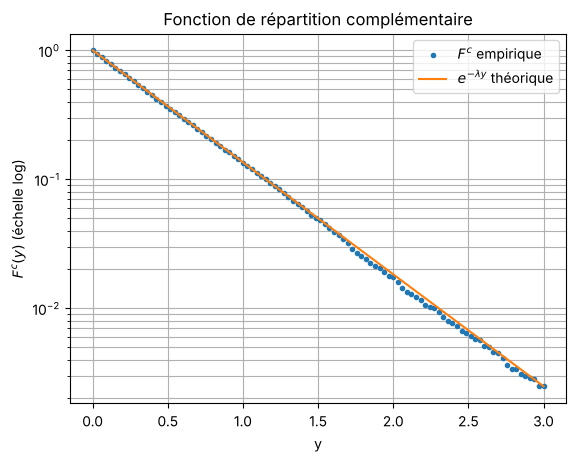

In [5]:
y_grille = np.linspace(0, 3, 100)
Fc_emp = np.array([np.mean(Y > t) for t in y_grille])   # F^c empirique
Fc_th = np.exp(-lam * y_grille)                          # F^c théorique

plt.semilogy(y_grille, Fc_emp, 'o', markersize=3, label="$F^c$ empirique")
plt.semilogy(y_grille, Fc_th, '-', label=r"$e^{-\lambda y}$ théorique")
plt.xlabel("y"); plt.ylabel("$F^c(y)$ (échelle log)")
plt.title("Fonction de répartition complémentaire")
plt.legend(); plt.grid(True, which="both")
plt.show()

In [6]:
y1, y2 = 0.5, 1.5
Fc1, Fc2 = np.mean(Y > y1), np.mean(Y > y2)

pente = (np.log(Fc2) - np.log(Fc1)) / (y2 - y1)
pente_th = (np.log(np.exp(-lam*y2)) - np.log(np.exp(-lam*y1))) / (y2 - y1)

print(f"F^c({y1}) empirique = {Fc1:.4f}   théorique = {np.exp(-lam*y1):.4f}")
print(f"F^c({y2}) empirique = {Fc2:.4f}   théorique = {np.exp(-lam*y2):.4f}")
print(f"Pente empirique = {pente:.3f}   pente théorique = {pente_th:.3f}")
print(f"λ estimé = {-pente:.3f}   (λ = {lam})")

F^c(0.5) empirique = 0.3618   théorique = 0.3679
F^c(1.5) empirique = 0.0492   théorique = 0.0498
Pente empirique = -1.995   pente théorique = -2.000
λ estimé = 1.995   (λ = 2)


**Commentaire.** Les points empiriques sont alignés sur une droite et suivent la courbe théorique : la décroissance est bien exponentielle. La pente estimée ($\approx -1.995$) est proche de $-\lambda = -2$. Pour $y$ grand ($y > 2.5$), les points s'écartent de la droite car peu de valeurs de l'échantillon dépassent $y$ (bruit statistique), d'où le choix de deux points dans la partie fiable.

---
## 1.2 Génération de variables gaussiennes par la méthode de Box-Muller

**Problème.** Pour la loi normale, $F^{-1}$ n'a pas de formule : la méthode d'inversion ne s'applique pas directement.

**Idée de Box-Muller.** On génère **deux** gaussiennes à la fois et on les voit comme un **point $(X_1, X_2)$ du plan**. En coordonnées polaires :
- le carré de la distance $r^2$ suit une loi **exponentielle** (qu'on sait générer, partie 1.1) ;
- l'angle $\theta$ est **uniforme** (nuage circulaire, aucune direction privilégiée).

**Rappel :** densité de $\mathcal{N}(0,1)$ : $\displaystyle f(x) = \frac{1}{\sqrt{2\pi}}\,e^{-x^2/2}$ (le facteur $1/\sqrt{2\pi}$ rend l'aire égale à 1).

**Coordonnées polaires :** $x_1 = r\cos\theta$, $x_2 = r\sin\theta$, $r^2 = x_1^2 + x_2^2$ (Pythagore), $\theta \in [0, 2\pi]$ (en radians).

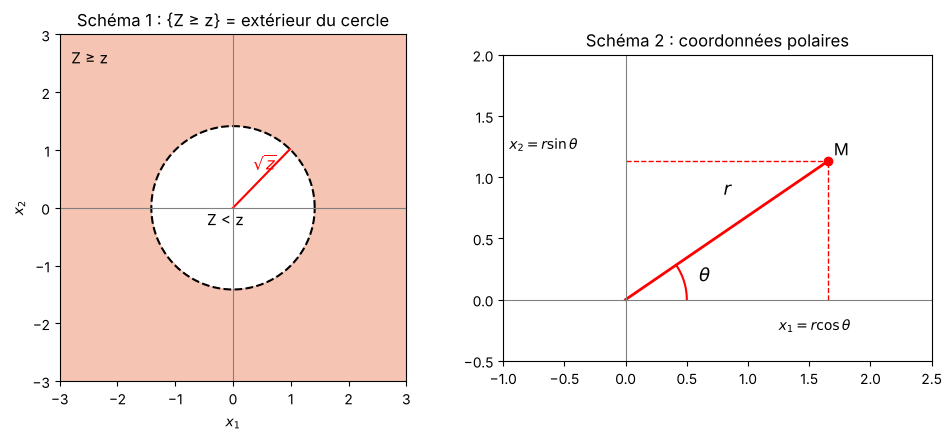

In [7]:
# Schémas : (1) l'événement {Z >= z} ; (2) coordonnées polaires
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))

z = 2; R = np.sqrt(z)
xx, yy = np.meshgrid(np.linspace(-3, 3, 400), np.linspace(-3, 3, 400))
ax[0].contourf(xx, yy, (xx**2 + yy**2 >= z).astype(float), levels=[0.5, 1.5], colors=["#f5c4b3"])
t = np.linspace(0, 2*np.pi, 200)
ax[0].plot(R*np.cos(t), R*np.sin(t), "k--")
ax[0].plot([0, R*np.cos(0.8)], [0, R*np.sin(0.8)], "r")
ax[0].text(0.35, 0.65, r"$\sqrt{z}$", color="r", fontsize=12)
ax[0].text(-0.45, -0.3, "Z < z", fontsize=11); ax[0].text(-2.8, 2.5, "Z ≥ z", fontsize=11)
ax[0].axhline(0, color="gray", lw=0.8); ax[0].axvline(0, color="gray", lw=0.8)
ax[0].set_aspect("equal"); ax[0].set_title("Schéma 1 : {Z ≥ z} = extérieur du cercle")
ax[0].set_xlabel("$x_1$"); ax[0].set_ylabel("$x_2$")

r, th = 2, 0.6
Mx, My = r*np.cos(th), r*np.sin(th)
ax[1].plot([0, Mx], [0, My], "r", lw=2); ax[1].plot(Mx, My, "ro")
ax[1].plot([Mx, Mx], [0, My], "r--", lw=1); ax[1].plot([0, Mx], [My, My], "r--", lw=1)
tt = np.linspace(0, th, 50); ax[1].plot(0.5*np.cos(tt), 0.5*np.sin(tt), "r")
ax[1].text(0.6, 0.15, r"$\theta$", fontsize=13); ax[1].text(0.8, 0.85, "$r$", fontsize=13)
ax[1].text(Mx-0.4, -0.25, r"$x_1 = r\cos\theta$"); ax[1].text(-0.95, My+0.1, r"$x_2 = r\sin\theta$")
ax[1].text(Mx+0.05, My+0.05, "M", fontsize=12)
ax[1].axhline(0, color="gray", lw=0.8); ax[1].axvline(0, color="gray", lw=0.8)
ax[1].set_xlim(-1, 2.5); ax[1].set_ylim(-0.5, 2); ax[1].set_aspect("equal")
ax[1].set_title("Schéma 2 : coordonnées polaires")
plt.tight_layout(); plt.show()

### Question 1 — $Z = X_1^2 + X_2^2$ suit la loi $\mathcal{E}(1/2)$

*Remarque : coquille dans l'énoncé. Pour $\lambda = 1/2$, il faut lire $P(Z \ge z) = e^{-z/2}$ (et non $e^{-2z}$).*

**Étape 1 — densité du couple.** $X_1, X_2$ indépendantes $\Rightarrow$ densité du couple = **produit** des densités ; on utilise $e^a e^b = e^{a+b}$ :
$$f(x_1, x_2) = \frac{1}{\sqrt{2\pi}}e^{-x_1^2/2}\cdot\frac{1}{\sqrt{2\pi}}e^{-x_2^2/2} = \frac{1}{2\pi}\,e^{-(x_1^2 + x_2^2)/2}$$
*La densité ne dépend que de $x_1^2 + x_2^2$ = (distance à l'origine)², pas de la direction : le nuage de points est **circulaire**.*

**Étape 2 — l'événement $\{Z \ge z\}$ et l'intégrale double.**
$$Z \ge z \iff x_1^2 + x_2^2 \ge z \iff \text{distance à l'origine} \ge \sqrt{z}$$
C'est l'**extérieur du cercle de rayon $\sqrt z$** (schéma 1). La probabilité est la somme de la densité sur cette région :
$$P(Z \ge z) = \iint_{x_1^2 + x_2^2 \ge z} \frac{1}{2\pi}\,e^{-(x_1^2 + x_2^2)/2}\;dx_1\,dx_2$$

**Étape 3 — passage en coordonnées polaires.** On remplace trois choses :
- (a) l'exposant : $x_1^2 + x_2^2 = r^2$, donc $e^{-(x_1^2+x_2^2)/2} = e^{-r^2/2}$ ;
- (b) la région : $r \ge \sqrt z$ et $\theta \in [0, 2\pi]$ (toutes les directions) ;
- (c) l'élément de surface (jacobien) : $dx_1\,dx_2 = r\,dr\,d\theta$ *(on découpe le plan « en parts de pizza » de côtés $dr$ et $r\,d\theta$ : les parts éloignées du centre sont plus grandes)*.
$$P(Z \ge z) = \int_0^{2\pi}\!\!\int_{\sqrt{z}}^{\infty} \frac{1}{2\pi}\, e^{-r^2/2}\; r\, dr\, d\theta$$

**Étape 4 — calcul.** $\theta$ n'apparaît pas dans la fonction : l'intégrale se sépare.
$$P(Z \ge z) = \underbrace{\frac{1}{2\pi}\int_0^{2\pi} d\theta}_{=\,\frac{2\pi}{2\pi}\,=\,1} \times \int_{\sqrt{z}}^{\infty} r\, e^{-r^2/2}\, dr$$

Primitive de $r\,e^{-r^2/2}$ : $-e^{-r^2/2}$. *(Vérification : $(e^{u})' = u'e^{u}$ avec $u = -r^2/2$, $u' = -r$, donc $(-e^{-r^2/2})' = r\,e^{-r^2/2}$.)*
$$\int_{\sqrt{z}}^{\infty} r\, e^{-r^2/2}\, dr = \Big[-e^{-r^2/2}\Big]_{\sqrt{z}}^{\infty} = 0 - \left(-e^{-(\sqrt z)^2/2}\right) = e^{-z/2}$$

**Conclusion :**
$$\boxed{P(Z \ge z) = e^{-z/2}, \quad z \ge 0}$$
C'est la fonction de répartition complémentaire de $\mathcal{E}(\lambda = 1/2)$ : $Z = X_1^2 + X_2^2 \sim \mathcal{E}(1/2)$, de moyenne $1/\lambda = 2$.

*Exemple : $P(Z \ge 2) = e^{-1} \approx 0.37$ : environ 37 % des points $(X_1, X_2)$ sont à une distance supérieure à $\sqrt2 \approx 1.41$ de l'origine.*

### Question 2 — Lois de $r^2$ et de $\theta$

**(A) Loi de $r^2$.** Par Pythagore $r^2 = X_1^2 + X_2^2 = Z$, et d'après Q1 :
$$\boxed{r^2 \sim \mathcal{E}(1/2)}$$

**(B) Loi de $\theta$.** En polaires, la densité devient $\frac{1}{2\pi}\,e^{-r^2/2}\,r$ : **$\theta$ n'y apparaît pas**, aucune direction n'est privilégiée.

Calcul de $P(\theta \le t)$ pour $t \in [0, 2\pi]$. *Choix des bornes :* l'événement $\{\theta \le t\}$ est le secteur entre l'axe $x_1$ ($\theta = 0$) et la demi-droite d'angle $t$ ; aucune condition sur la distance ($r$ de $0$ à $\infty$), condition sur l'angle ($\theta$ de $0$ à $t$). *(En Q1 c'était l'inverse : condition $r \ge \sqrt z$, angle quelconque.)*
$$P(\theta \le t) = \int_0^{t}\!\!\int_0^{\infty} \frac{1}{2\pi}\, e^{-r^2/2}\, r\, dr\, d\theta = \frac{1}{2\pi}\int_0^{t} d\theta \times \int_0^{\infty} r\, e^{-r^2/2}\, dr$$

- partie distance : $\Big[-e^{-r^2/2}\Big]_0^{\infty} = 0 - (-e^0) = 1$ ;
- partie angle : $\dfrac{1}{2\pi}\displaystyle\int_0^t d\theta = \dfrac{t}{2\pi}$.

$$P(\theta \le t) = \frac{t}{2\pi} \qquad (t = 0 \to 0,\ \ t = \pi \to \tfrac12,\ \ t = 2\pi \to 1)$$

La probabilité est la **fraction du tour complet**, comme $P(U \le a) = a$ pour $\mathcal{U}[0,1]$ :
$$\boxed{\theta \sim \mathcal{U}[0, 2\pi]}$$

*Remarque :* la densité en polaires est un produit (partie en $\theta$) × (partie en $r$) : **$r$ et $\theta$ sont indépendants**.

> **Идея своими словами.** $r^2$ — это и есть $Z$ из Q1. Облако круглое, поэтому все направления равновероятны: вероятность угла — доля полного оборота.

### Question 3 — Méthode de Box-Muller

On **inverse le raisonnement** de Q2 : si on génère $r$ et $\theta$ avec les bonnes lois (et indépendants), le point $(r\cos\theta, r\sin\theta)$ a la loi d'un couple de deux $\mathcal{N}(0,1)$ indépendantes.

**Recette** ($U_1, U_2$ indépendantes $\sim \mathcal{U}[0,1]$) :
1. **Distance :** $r^2 \sim \mathcal{E}(1/2)$ par inversion (partie 1.1) :
$$r^2 = -\frac{\ln(1-U_1)}{1/2} = -2\ln(1-U_1) \quad\Rightarrow\quad r = \sqrt{-2\ln(1-U_1)}$$
2. **Angle :** $\theta = 2\pi\,U_2$ (on étire $U_2$ sur un tour complet, **en radians**).
3. **Retour en cartésiennes :** $X_1 = r\cos\theta$, $\quad X_2 = r\sin\theta$.

*Deux nombres uniformes donnent deux nombres gaussiens indépendants.*

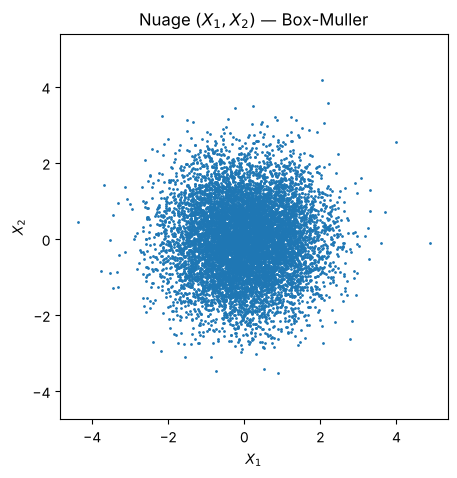

Moyenne de r² = 1.970   (théorie : 1/λ = 2)
Proportion Z >= 2 = 0.364   (théorie : e^(-1) = 0.368)


In [8]:
T = 10000
U1 = np.random.rand(T)                  # pour la distance
U2 = np.random.rand(T)                  # pour l'angle

r = np.sqrt(-2 * np.log(1 - U1))        # r² ~ E(1/2)
theta = 2 * np.pi * U2                  # θ ~ U[0, 2π]

X1 = r * np.cos(theta)
X2 = r * np.sin(theta)

plt.figure(figsize=(5, 5))
plt.scatter(X1, X2, s=1)
plt.axis("equal"); plt.xlabel("$X_1$"); plt.ylabel("$X_2$")
plt.title("Nuage $(X_1, X_2)$ — Box-Muller")
plt.show()

print(f"Moyenne de r² = {np.mean(r**2):.3f}   (théorie : 1/λ = 2)")
print(f"Proportion Z >= 2 = {np.mean(r**2 >= 2):.3f}   (théorie : e^(-1) = {np.exp(-1):.3f})")

**Commentaire.** Le nuage est **circulaire** (aucune direction privilégiée : $\theta$ uniforme) et **plus dense au centre** (cloche en deux dimensions). La moyenne de $r^2$ ($\approx 1.97$) et la proportion $P(Z \ge 2) \approx 0.364$ (théorie $0.368$) confirment le résultat de Q1 : $r^2 \sim \mathcal{E}(1/2)$.

### Question 4 — De $\mathcal{N}(0,1)$ à $\mathcal{N}(\mu, \sigma^2)$

**Transformation linéaire :** si $X \sim \mathcal{N}(0,1)$, alors
$$\boxed{Y = \mu + \sigma X \sim \mathcal{N}(\mu, \sigma^2)}$$

**Idée :** on **étire** la cloche standard d'un facteur $\sigma$ (largeur $\sigma$, centre toujours en 0), puis on la **décale** de $\mu$ (centre en $\mu$, même largeur). Comme une conversion d'unités ($F = 32 + 1.8\,C$).

**Moyenne et variance.** Avec $E[aX+b] = a\,E[X] + b$, $\text{Var}(aX+b) = a^2\,\text{Var}(X)$, $E[X] = 0$, $\text{Var}(X) = 1$ :
$$E[Y] = \sigma\cdot 0 + \mu = \mu, \qquad \text{Var}(Y) = \sigma^2\cdot 1 = \sigma^2$$
*(le décalage $\mu$ ne change pas la variance : il déplace la cloche sans l'élargir)*

**Forme gaussienne conservée** ($\sigma > 0$, l'inégalité garde son sens) :
$$P(Y \le y) = P(\mu + \sigma X \le y) = P\!\left(X \le \frac{y-\mu}{\sigma}\right)$$

**Application :** $\mu = 5$, $\sigma^2 = 4$ $\Rightarrow$ $\sigma = \sqrt4 = 2$ (**attention : $\sigma$ et non $\sigma^2$**) :
$$Y = 5 + 2X, \qquad X = X_1 \text{ généré par Box-Muller (Q3)}$$
*Exemple : $X = 0 \to Y = 5$ (centre) ; $X = 1 \to Y = 7$ (un écart type à droite).*


In [9]:
mu = 5
sigma = 2                        # σ = √4 car σ² = 4
Yg = mu + sigma * X1             # Yg ~ N(5, 4)  (nouveau nom pour ne pas écraser Y de la partie 1.1)

print("Premières valeurs :", np.round(Yg[:5], 3))

Premières valeurs : [ 6.715 -0.319  5.622  4.587  4.457]


### Question 5 — Vérification : moyenne, variance, histogramme

**Valeurs attendues :** $E[Y] = \mu = 5$, $\text{Var}(Y) = \sigma^2 = 4$.

**Règle des trois sigmas** pour une loi normale : environ 68 % des valeurs dans $\mu \pm \sigma$, 95 % dans $\mu \pm 2\sigma$, 99.7 % dans $\mu \pm 3\sigma$. Ici : $[3, 7]$, $[1, 9]$, $[-1, 11]$.

Densité théorique de $\mathcal{N}(\mu, \sigma^2)$ : $\displaystyle f(y) = \frac{1}{\sigma\sqrt{2\pi}}\,e^{-(y-\mu)^2/(2\sigma^2)}$ ; pic en $y = \mu$ de hauteur $\frac{1}{\sigma\sqrt{2\pi}} \approx 0.199$.

Moyenne empirique  : 5.0145    théorie μ  = 5
Variance empirique : 3.8975    théorie σ² = 4
Proportion dans μ ± 1σ = [3, 7] : 0.687   (théorie ≈ 0.683)
Proportion dans μ ± 2σ = [1, 9] : 0.957   (théorie ≈ 0.954)
Proportion dans μ ± 3σ = [-1, 11] : 0.997   (théorie ≈ 0.997)


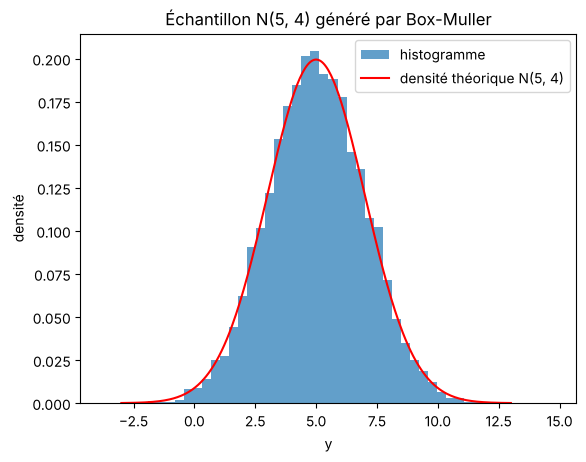

In [10]:
print(f"Moyenne empirique  : {np.mean(Yg):.4f}    théorie μ  = {mu}")
print(f"Variance empirique : {np.var(Yg, ddof=1):.4f}    théorie σ² = {sigma**2}")
for k, th in [(1, 0.683), (2, 0.954), (3, 0.997)]:
    print(f"Proportion dans μ ± {k}σ = [{mu-k*sigma}, {mu+k*sigma}] : {np.mean(abs(Yg-mu) <= k*sigma):.3f}   (théorie ≈ {th})")

y = np.linspace(-3, 13, 300)
f_th = 1 / (sigma*np.sqrt(2*np.pi)) * np.exp(-(y - mu)**2 / (2*sigma**2))

plt.hist(Yg, bins=50, density=True, alpha=0.7, label="histogramme")
plt.plot(y, f_th, "r", label="densité théorique N(5, 4)")
plt.xlabel("y"); plt.ylabel("densité"); plt.legend()
plt.title("Échantillon N(5, 4) généré par Box-Muller")
plt.show()

**Commentaire.** La moyenne empirique ($\approx 5.01$) et la variance empirique ($\approx 3.90$) sont cohérentes avec les valeurs prescrites $\mu = 5$ et $\sigma^2 = 4$. L'histogramme a une forme de cloche symétrique centrée en 5, qui suit la densité théorique ; les proportions dans $\mu \pm \sigma$, $\mu \pm 2\sigma$, $\mu \pm 3\sigma$ correspondent à la règle 68 / 95 / 99.7 %, et presque toutes les valeurs sont entre $-1$ et $11$. La méthode de Box-Muller génère bien la loi $\mathcal{N}(5, 4)$.

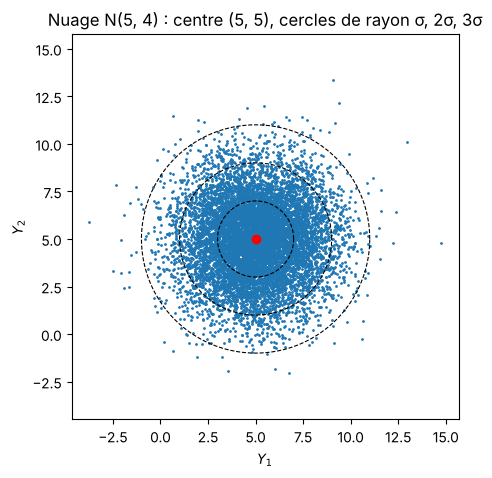

In [11]:
# Bonus : le nuage (Y1, Y2) = (5 + 2 X1, 5 + 2 X2) est décalé en (5, 5) et étiré d'un facteur 2
plt.figure(figsize=(5, 5))
plt.scatter(mu + sigma*X1, mu + sigma*X2, s=1)
plt.scatter(mu, mu, color="red")
t = np.linspace(0, 2*np.pi, 200)
for k in [1, 2, 3]:
    plt.plot(mu + k*sigma*np.cos(t), mu + k*sigma*np.sin(t), "k--", lw=0.8)
plt.axis("equal"); plt.xlabel("$Y_1$"); plt.ylabel("$Y_2$")
plt.title("Nuage N(5, 4) : centre (5, 5), cercles de rayon σ, 2σ, 3σ")
plt.show()

---
## Conclusion

- La **méthode d'inversion** est la plus simple : dès qu'on sait inverser $F$ par une formule (ici $\mathcal{E}(\lambda)$), une seule ligne de code suffit : $Y = F^{-1}(U)$.
- Pour la **loi gaussienne**, $F^{-1}$ n'a pas de formule. **Box-Muller** contourne le problème en passant en coordonnées polaires : la distance au carré est exponentielle (on réutilise la partie 1.1) et l'angle est uniforme.
- Dans tous les cas, moyennes, variances, proportions et graphiques empiriques sont cohérents avec la théorie, avec des écarts de l'ordre de $\sigma/\sqrt T$.

---
## Fiche de révision — notions à savoir expliquer à l'oral

| Notion | À dire en une phrase |
|---|---|
| Fonction de répartition $F(y)$ | Proportion des valeurs $\le y$ ; croissante de 0 à 1. |
| Densité $f = F'$ | « Où les valeurs sont fréquentes » ; l'aire sous $f$ entre $a$ et $b$ = probabilité ; aire totale = 1. |
| Méthode d'inversion | $U$ = pourcentage aléatoire, $F^{-1}$ le transforme en valeur : $Y = F^{-1}(U)$ a la f.d.r. $F$. |
| Loi exponentielle | Temps d'attente ; $F(y) = 1 - e^{-\lambda y}$, $F^{-1}(u) = -\ln(1-u)/\lambda$, $E = 1/\lambda$, $\text{Var} = 1/\lambda^2$. |
| Espérance | Moyenne pondérée : valeur × fréquence, intégrée. |
| Échelle semi-log | $\ln$ transforme $e^{-\lambda y}$ en droite de pente $-\lambda$ : on vérifie l'exponentielle et on estime $\lambda$. |
| Box-Muller | Deux gaussiennes = un point ; $r^2 \sim \mathcal{E}(1/2)$, $\theta \sim \mathcal{U}[0,2\pi]$ ; $X_1 = r\cos\theta$, $X_2 = r\sin\theta$. |
| Coordonnées polaires | $dx_1\,dx_2 = r\,dr\,d\theta$ ; le cercle devient « $r \ge \sqrt z$ ». |
| $\mathcal{N}(\mu,\sigma^2)$ | $Y = \mu + \sigma X$ : étirer puis décaler ; règle 68 / 95 / 99.7 %. |
| Erreur empirique | De l'ordre de $\sigma/\sqrt{T}$ : diminue quand $T$ augmente. |